# Driver Analysis of Hypoxia Trend

This notebook identifies the environmental and nutrient drivers that distinguish stations with worsening localized hypoxia from those with improving regional hypoxia trends. 

**Goal:** Determine if "Worsening Local" stations are driven by different mechanisms (e.g., local nutrient loading) compared to "Improving Regional" stations (e.g., broad climatic signals).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd
from matplotlib.lines import Line2D
from scipy import stats
import yaml
from pathlib import Path
import sys
import os

# Resolve project root and add to sys.path
cwd = Path(os.getcwd())
if (cwd / 'params.yaml').exists():
    project_root = cwd
else:
    project_root = cwd.parent
    
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))
if str(project_root / 'scripts') not in sys.path:
    sys.path.append(str(project_root / 'scripts'))

from scripts.paths import ProjectPaths
from scripts.mapping_config import MappingConfig
from scripts.data_loader import load_and_process_data

# Apply the global project style
plt.style.use('../project_style.mplstyle')

# Load parameters
with open(project_root / 'params.yaml', 'r') as f:
    params = yaml.safe_load(f)

TARGET_REGION = params['mapping']['target_region']
REGION_COLUMN = params['mapping']['region_column']
REP_MONTH_SUMMER = params['seasonal_subsets']['representative_months']['Summer']

print(f"Target Region: {TARGET_REGION}")


Target Region: Seto Inland Sea


## 1. Data Preparation and Trend Calculation

We calculate the Hypoxia Trend ($\Delta P$) using a threshold of **5.0 mg/L**. 
*   **Historical Frequency ($P_{hist}$):** 1981–2013 (Normalized over 33 years).
*   **Recent Frequency ($P_{recent}$):** 2014–2023 (Normalized over 10 years).
*   **Trend ($\Delta P$):** Recent frequency - Historical frequency ($P_{recent} - P_{hist}$).

We then merge this trend data with the **Decorrelation Scales** calculated in Stage 08 to add spatial context to the temporal trends.

In [2]:
# 1. Concise Data Loading & Trend Calculation
LOW_DO_THRESHOLD = 5.0

print("Loading data...")
merged_gdf = load_and_process_data(force_reload=False)
merged_gdf['zettaicode'] = merged_gdf['zettaicode'].astype(str).str.zfill(8)

# Filter for Target Region and Summer Bottom
df = merged_gdf[merged_gdf[REGION_COLUMN] == TARGET_REGION].copy()
summer_bottom = df[
    (df['surveymont'] == REP_MONTH_SUMMER) &
    (df['saisuipoin'] == 2)
].copy()
summer_bottom['do_'] = pd.to_numeric(summer_bottom['do_'], errors='coerce')
summer_bottom = summer_bottom.dropna(subset=['do_'])

# Pivot data
pivot_df = summer_bottom.pivot_table(index='zettaicode', columns='year', values='do_', aggfunc='mean')
pivot_df.index = pivot_df.index.astype(str).str.zfill(8)

# Calculate Trend
years = pivot_df.columns.astype(int)
hist_years = [y for y in years if 1981 <= y <= 2013]
recent_years = [y for y in years if 2014 <= y <= 2023]

p_hist = (pivot_df[hist_years] < LOW_DO_THRESHOLD).sum(axis=1) / 33
p_recent = (pivot_df[recent_years] < LOW_DO_THRESHOLD).sum(axis=1) / 10
delta = p_recent - p_hist

# Coordinates
coords = summer_bottom.groupby('zettaicode')[['latitude', 'longitude']].first()

# Decorrelation Scale
subset_dir = ProjectPaths.get_subset_dir('Summer', 'bottom')
decorr_file = subset_dir / "stations_decorrelation_scale.csv"
if decorr_file.exists():
    df_decorr = pd.read_csv(decorr_file, dtype={'Station_ID': str})
    df_decorr['Station_ID'] = df_decorr['Station_ID'].str.zfill(8)
else:
    print(f"Warning: {decorr_file} not found.")
    df_decorr = pd.DataFrame(columns=['Station_ID', 'Decorrelation_Scale_km'])

# Combine
map_df = pd.DataFrame({
    'delta': delta,
    'p_recent': p_recent,
    'lat': coords['latitude'],
    'lon': coords['longitude']
}).dropna().reset_index().rename(columns={'zettaicode': 'Station_ID'})

stats_df = map_df.merge(
    df_decorr[['Station_ID', 'Decorrelation_Scale_km']], 
    on='Station_ID', 
    how='inner'
)
print(f"Total stations with trend and decorrelation data: {len(stats_df)}")


Loading data...
Loading processed data from /home/reyha/SIS_Analysis_WSL/data/processed/merged_gdf.feather...
Total stations with trend and decorrelation data: 124


## 2. Station Selection and Grouping

We isolate two distinct groups of stations based on their spatial and temporal characteristics:
*   **Group 1 (Local & Worsening):** Stations with high localized variability (Decorrelation Scale < 20 km) and increasing hypoxia frequency ($\Delta P > 0$).
*   **Group 2 (Regional & Improving):** Stations with broad regional signals (Decorrelation Scale > 10 km) and decreasing hypoxia frequency ($\Delta P < -0.2$).


In [3]:
# 2. Group Selection
# Group 1 (Local & Worsening): Decorrelation_Scale_km < 20 & delta > 0
# Group 2 (Regional & Improving): Decorrelation_Scale_km > 10 & delta < -0.2

group1_mask = (stats_df['Decorrelation_Scale_km'] < 20) & (stats_df['delta'] > 0)
group2_mask = (stats_df['Decorrelation_Scale_km'] > 10) & (stats_df['delta'] < -0.2)

stats_df['Group'] = 'Other'
stats_df.loc[group1_mask, 'Group'] = 'Group 1 (Local & Worsening)'
stats_df.loc[group2_mask, 'Group'] = 'Group 2 (Regional & Improving)'

selected_stations = stats_df[stats_df['Group'] != 'Other'].copy()
print(f"Group 1 count: {len(selected_stations[selected_stations['Group'] == 'Group 1 (Local & Worsening)'])}")
print(f"Group 2 count: {len(selected_stations[selected_stations['Group'] == 'Group 2 (Regional & Improving)'])}")


Group 1 count: 15
Group 2 count: 8


## 3. Geospatial Visualization

We visualize the selected stations using two mapping techniques to ensure spatial consistency:
1.  **Bivariate Trend Map:** Sized by recent severity ($P_{recent}$) and colored by the continuous trend ($\Delta P$).
2.  **Discrete Group Map:** Categorical labeling with **Zettaicode annotations** to identify specific locations for localized case studies.

/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '
/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


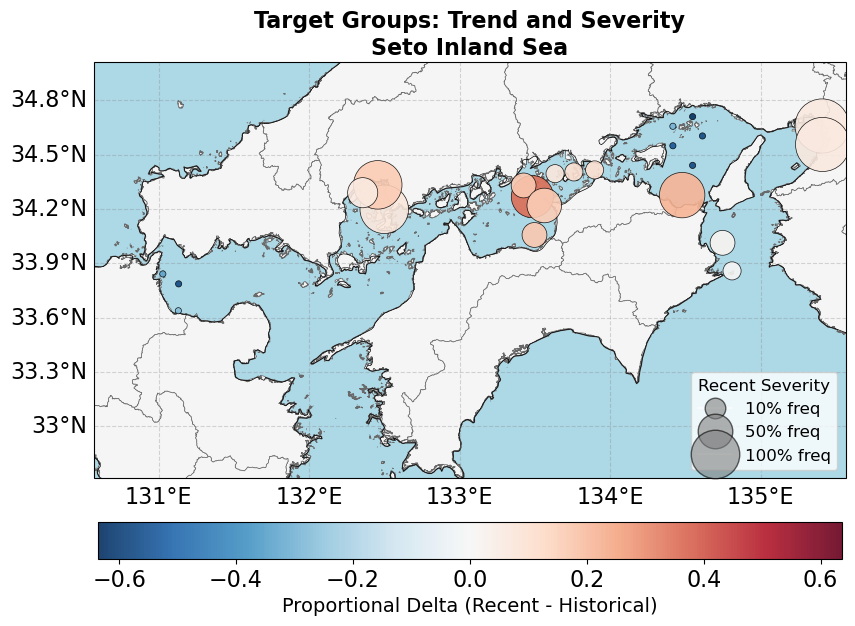

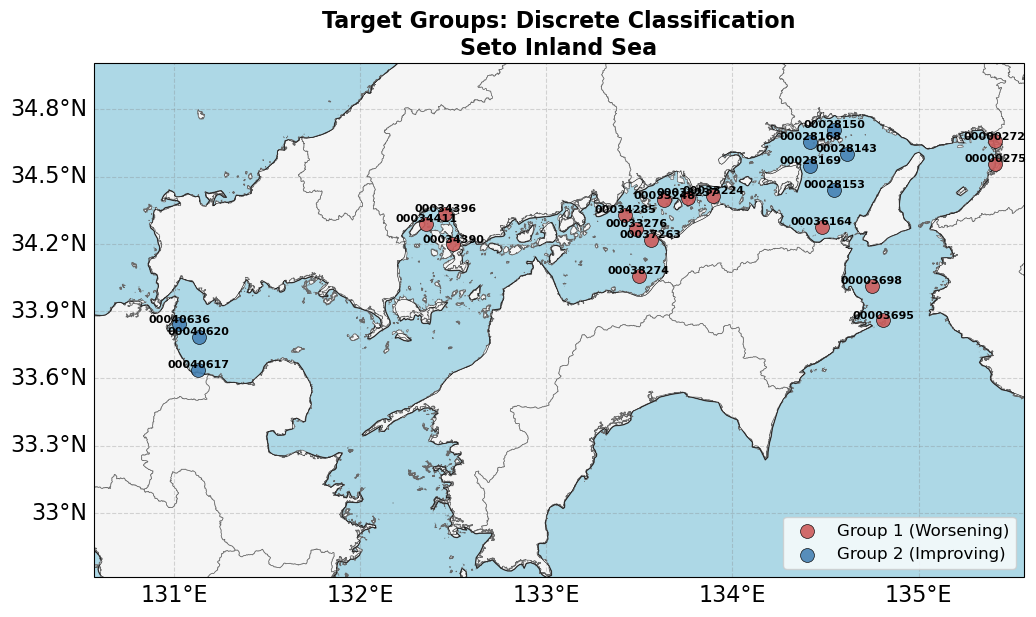

In [4]:
# 3. Mapping Selected Stations (Two Separate Figures)
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.lines import Line2D

# Prepare map boundaries and features
water_boundary_path = ProjectPaths.BOUNDARIES_DIR / "SIS water mass polygon" / "sea_area_mask_simplified.shp"
sis_water_boundary = gpd.read_file(water_boundary_path)
if sis_water_boundary.crs != "EPSG:4326":
    sis_water_boundary = sis_water_boundary.to_crs("EPSG:4326")
bounds = sis_water_boundary.total_bounds

land_boundary_file = "polbnda_jpn.shp" # Default fallback
if hasattr(MappingConfig, 'get_boundary_file'):
    land_boundary_file = MappingConfig.get_boundary_file(TARGET_REGION)
land_boundary_path = ProjectPaths.BOUNDARIES_DIR / "SIS_prefecture_boundaries" / land_boundary_file
if land_boundary_path.exists():
    sis_land_boundary = gpd.read_file(land_boundary_path)
    if sis_land_boundary.crs != "EPSG:4326":
        sis_land_boundary = sis_land_boundary.to_crs("EPSG:4326")
else:
    sis_land_boundary = None

extent = [bounds[0]+0.1, bounds[2]+0.1, bounds[1]-0, bounds[3]+0.2]
aspect_ratio = (extent[3] - extent[2]) / (extent[1] - extent[0])
fig_width = 12
fig_height = (fig_width * aspect_ratio) + 1.5

# --- Figure 1: Continuous Delta & Size ---
fig1, ax1 = plt.subplots(figsize=(fig_width, fig_height), subplot_kw={'projection': ccrs.PlateCarree()})
ax1.set_facecolor(MappingConfig.COLOR_OCEAN if hasattr(MappingConfig, 'COLOR_OCEAN') else 'lightblue')
ax1.add_feature(cfeature.LAND, facecolor='#f5f5f5', edgecolor='dimgray', zorder=0)
ax1.add_feature(cfeature.COASTLINE, linewidth=0.5, color='black', zorder=2)
if sis_land_boundary is not None:
    sis_land_boundary.plot(ax=ax1, facecolor='#f5f5f5', edgecolor='dimgray', linewidth=0.5, transform=ccrs.PlateCarree(), zorder=1)

gl1 = ax1.gridlines(draw_labels=True, linestyle='--', color='gray', alpha=0.3, zorder=2)
gl1.top_labels = False
gl1.right_labels = False
ax1.set_extent(extent, crs=ccrs.PlateCarree())

vmax = max(abs(selected_stations['delta'].min()), abs(selected_stations['delta'].max()), 0.1)
sc1 = ax1.scatter(
    selected_stations['lon'], selected_stations['lat'],
    c=selected_stations['delta'],
    s=selected_stations['p_recent'] * 1500 + 20, 
    cmap='RdBu_r', vmin=-vmax, vmax=vmax,
    edgecolors='black', linewidths=0.5, alpha=0.9, transform=ccrs.PlateCarree(), zorder=3
)
cbar1 = plt.colorbar(sc1, ax=ax1, orientation='horizontal', pad=0.08, shrink=0.8)
cbar1.set_label('Proportional Delta (Recent - Historical)', fontsize=14)

# Size Legend
sizes = [0.2, 0.6, 1.2]
labels = ['10% freq', '50% freq', '100% freq']
legend_elements = [Line2D([0], [0], marker='o', color='w', label=l,
                          markerfacecolor='gray', markersize=np.sqrt(s * 1000 + 20),
                          markeredgecolor='k', alpha=0.6) for s, l in zip(sizes, labels)]
ax1.legend(handles=legend_elements, loc='lower right', title='Recent Severity', fontsize=12, title_fontsize=12)
ax1.set_title(f'Target Groups: Trend and Severity\n{TARGET_REGION}', fontsize=16, fontweight='bold')

map_output1 = ProjectPaths.FIGURES_DIR / f'lowDO_selected_stations_trend_{TARGET_REGION.replace(" ", "_")}.png'
plt.savefig(map_output1, dpi=300, bbox_inches='tight')

# --- Figure 2: Discrete Groups with Labels ---
fig2, ax2 = plt.subplots(figsize=(fig_width, fig_height), subplot_kw={'projection': ccrs.PlateCarree()})
ax2.set_facecolor(MappingConfig.COLOR_OCEAN if hasattr(MappingConfig, 'COLOR_OCEAN') else 'lightblue')
ax2.add_feature(cfeature.LAND, facecolor='#f5f5f5', edgecolor='dimgray', zorder=0)
ax2.add_feature(cfeature.COASTLINE, linewidth=0.4, color='black', zorder=2)
if sis_land_boundary is not None:
    sis_land_boundary.plot(ax=ax2, facecolor='#f5f5f5', edgecolor='dimgray', linewidth=0.5, transform=ccrs.PlateCarree(), zorder=1)

gl2 = ax2.gridlines(draw_labels=True, linestyle='--', color='gray', alpha=0.3, zorder=2)
gl2.top_labels = False
gl2.right_labels = False
ax2.set_extent(extent, crs=ccrs.PlateCarree())

g1 = selected_stations[selected_stations['Group'] == 'Group 1 (Local & Worsening)']
g2 = selected_stations[selected_stations['Group'] == 'Group 2 (Regional & Improving)']

ax2.scatter(g1['lon'], g1['lat'], c='indianred', s=100, edgecolors='black', linewidths=0.5, alpha=0.9, transform=ccrs.PlateCarree(), zorder=3, label='Group 1 (Worsening)')
ax2.scatter(g2['lon'], g2['lat'], c='steelblue', s=100, edgecolors='black', linewidths=0.5, alpha=0.9, transform=ccrs.PlateCarree(), zorder=3, label='Group 2 (Improving)')

# Add station ID labels
for idx, row in selected_stations.iterrows():
    ax2.text(row['lon'], row['lat'], row['Station_ID'], 
             transform=ccrs.PlateCarree(), fontsize=8, fontweight='bold',
             ha='center', va='bottom', zorder=4)

ax2.legend(loc='lower right', fontsize=12)
ax2.set_title(f'Target Groups: Discrete Classification\n{TARGET_REGION}', fontsize=16, fontweight='bold')

map_output2 = ProjectPaths.FIGURES_DIR / f'lowDO_selected_stations_discrete_{TARGET_REGION.replace(" ", "_")}.png'
plt.savefig(map_output2, dpi=300, bbox_inches='tight')

plt.show()

## 4. Regional Sensitivity Analysis (PCA-based)

We compare the sensitivity of regional DO patterns (derived from PCA) to environmental factors across the two groups. 
*   **Method:** Mann-Whitney U test on the per-station Pearson $r$ correlations between PCA scores and drivers (from Notebooks 34 & 35).
*   **Statistical Significance:** A $p$-value $< 0.05$ indicates that the two groups respond to that factor in fundamentally different ways.


### PC1

Calculating Summer Chl-a correlations...


/tmp/ipykernel_916/274039066.py:79: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=analysis_df, x='Group', y=param, ax=ax, palette=['indianred', 'steelblue'], showfliers=False)
/tmp/ipykernel_916/274039066.py:85: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Group 1', 'Group 2'])
/tmp/ipykernel_916/274039066.py:79: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=analysis_df, x='Group', y=param, ax=ax, palette=['indianred', 'steelblue'], showfliers=False)
/tmp/ipykernel_916/274039066.py:85: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after 

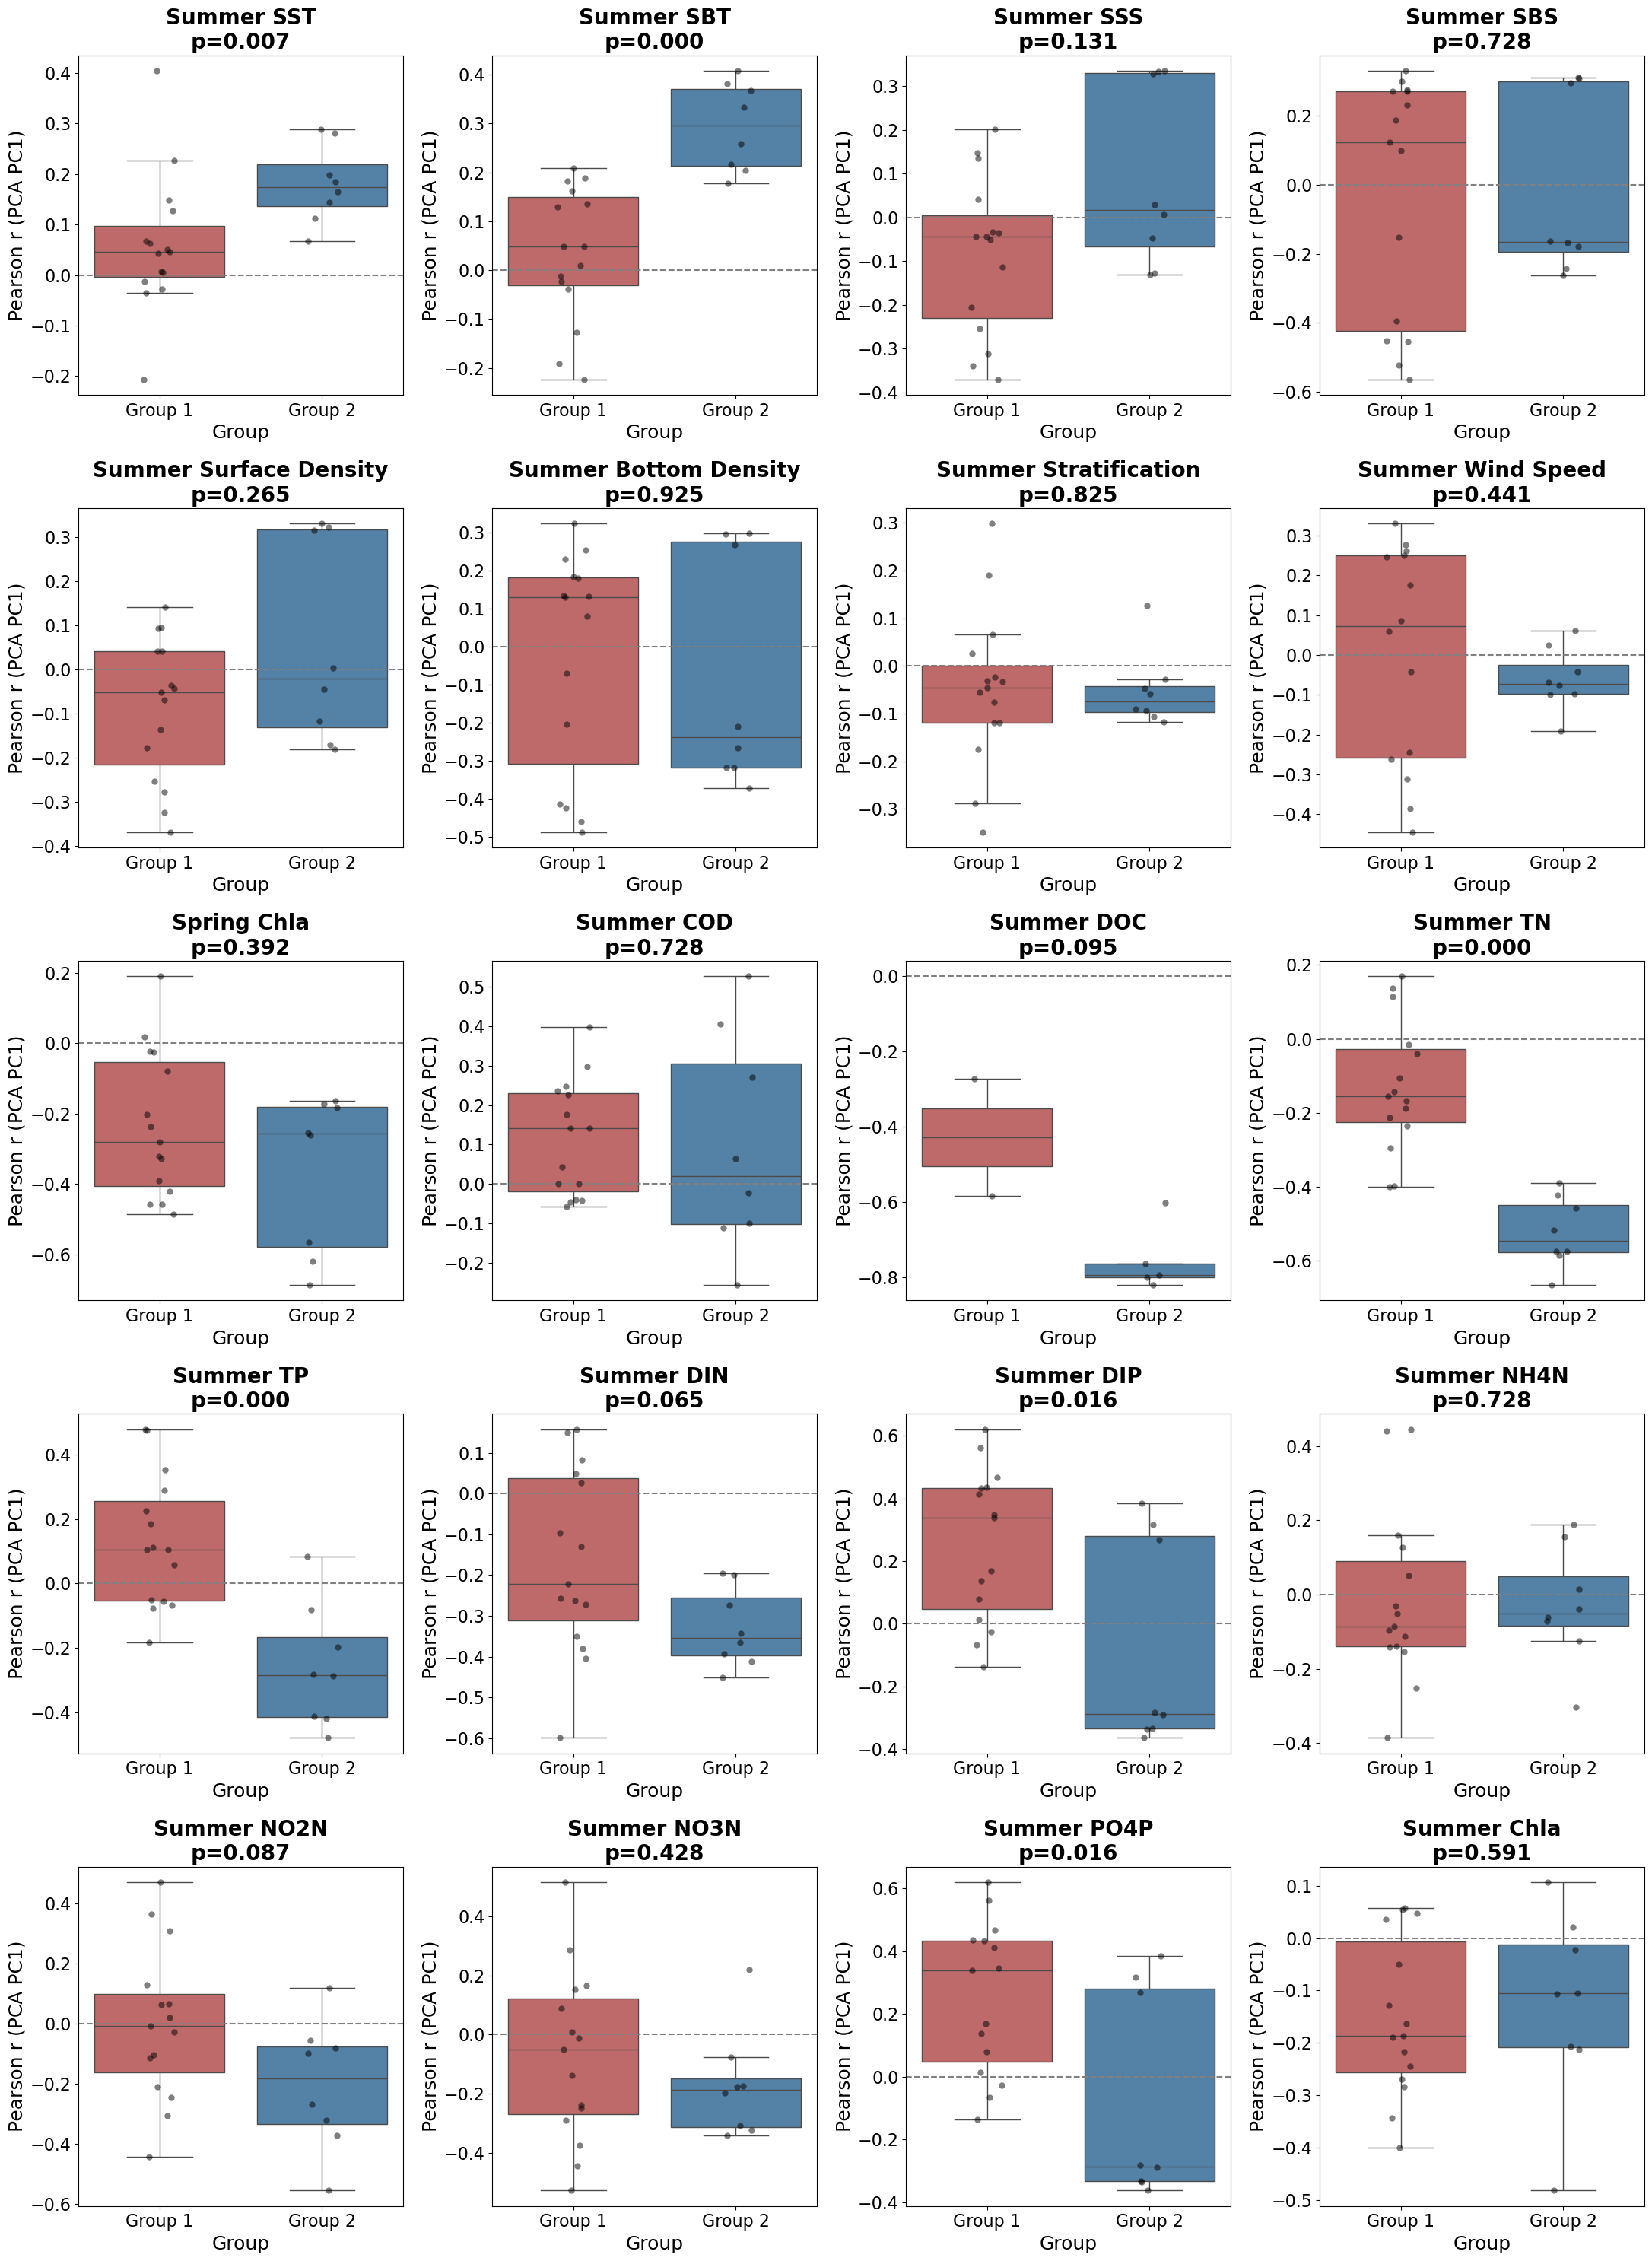

In [5]:
# 4. Driver Analysis (PCA Correlation Scores)
import math
from scipy.stats import pearsonr

# Increase global font sizes by 4 points
# Assuming base was ~12, we move to 16/18/20
plt.rcParams.update({
    'font.size': 16,
    'axes.labelsize': 18,
    'axes.titlesize': 20,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'legend.fontsize': 16
})

# Load correlation data
corr_pc1_env = pd.read_csv(subset_dir / 'pca_env_corr_pc1.csv', dtype={'zettaicode': str})
corr_pc1_nutr = pd.read_csv(subset_dir / 'pca_nutr_corr_pc1.csv', dtype={'zettaicode': str})

# Filter parameters: Remove Winter_Air_Temp
params_env = [c for c in corr_pc1_env.columns if c != 'zettaicode' and not c.endswith('_pval') and not c.endswith('_n') and c != 'Winter_Air_Temp']
params_nutr = [c for c in corr_pc1_nutr.columns if c != 'zettaicode' and not c.endswith('_pval') and not c.endswith('_n')]

pca_corr = corr_pc1_env[['zettaicode'] + params_env].rename(columns={c: f"{c}_Corr_PC1" for c in params_env})
pca_corr = pca_corr.merge(corr_pc1_nutr[['zettaicode'] + params_nutr].rename(columns={c: f"{c}_Corr_PC1" for c in params_nutr}), on='zettaicode', how='outer')

# Join with selected stations
analysis_df = selected_stations.merge(pca_corr, left_on='Station_ID', right_on='zettaicode', how='inner')

# --- Add Summer Chl-a Calculation (if missing) ---
if 'Summer_Chla_Corr_PC1' not in analysis_df.columns:
    print("Calculating Summer Chl-a correlations...")
    pca_scores = pd.read_csv(subset_dir / 'pca_scores.csv', index_col=0)
    pca_scores.index = pca_scores.index.astype(int)
    
    # Get Summer Bottom Chl-a Matrix
    mask = (merged_gdf['season'] == 'Summer') & (merged_gdf['saisuipoin'] == 2)
    chla_mat = merged_gdf[mask].groupby(['year', 'zettaicode'])['chlorophyl'].mean().unstack()
    
    chla_corrs = {}
    for stn in analysis_df['Station_ID'].unique():
        if stn in chla_mat.columns:
            s_pc = pca_scores['PC1']
            s_env = chla_mat[stn]
            common = s_pc.index.intersection(s_env.index)
            valid = s_pc.loc[common].notna() & s_env.loc[common].notna()
            if valid.sum() >= 5:
                r, _ = pearsonr(s_pc.loc[common][valid], s_env.loc[common][valid])
                chla_corrs[stn] = r
    
    analysis_df['Summer_Chla_Corr_PC1'] = analysis_df['Station_ID'].map(chla_corrs)

# Final list of parameters to test
params_to_test = [f"{p}_Corr_PC1" for p in params_env + params_nutr]
if 'Summer_Chla_Corr_PC1' not in params_to_test:
    params_to_test.append('Summer_Chla_Corr_PC1')

# Statistical Testing and Plotting
n_cols = 4
n_rows = math.ceil(len(params_to_test) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(22, 6 * n_rows))
axes = axes.flatten()

for i, param in enumerate(params_to_test):
    ax = axes[i]
    if param not in analysis_df.columns or analysis_df[param].dropna().empty:
        fig.delaxes(ax)
        continue
        
    g1_vals = analysis_df[analysis_df['Group'] == 'Group 1 (Local & Worsening)'][param].dropna()
    g2_vals = analysis_df[analysis_df['Group'] == 'Group 2 (Regional & Improving)'][param].dropna()
    
    if len(g1_vals) > 0 and len(g2_vals) > 0:
        stat, p = stats.mannwhitneyu(g1_vals, g2_vals, alternative='two-sided')
        p_str = f"p={p:.3f}"
    else:
        p_str = "N/A"
        
    sns.boxplot(data=analysis_df, x='Group', y=param, ax=ax, palette=['indianred', 'steelblue'], showfliers=False)
    sns.stripplot(data=analysis_df, x='Group', y=param, ax=ax, color='black', alpha=0.5, size=6, jitter=True)
    
    title = param.replace('_Corr_PC1', '').replace('_', ' ')
    ax.set_title(f"{title}\n{p_str}")
    ax.set_ylabel('Pearson r (PCA PC1)')
    ax.set_xticklabels(['Group 1', 'Group 2'])
    ax.axhline(0, color='gray', linestyle='--')

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

/tmp/ipykernel_916/2093332895.py:35: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=melted_df, x='Parameter', y='Correlation', hue='Group',


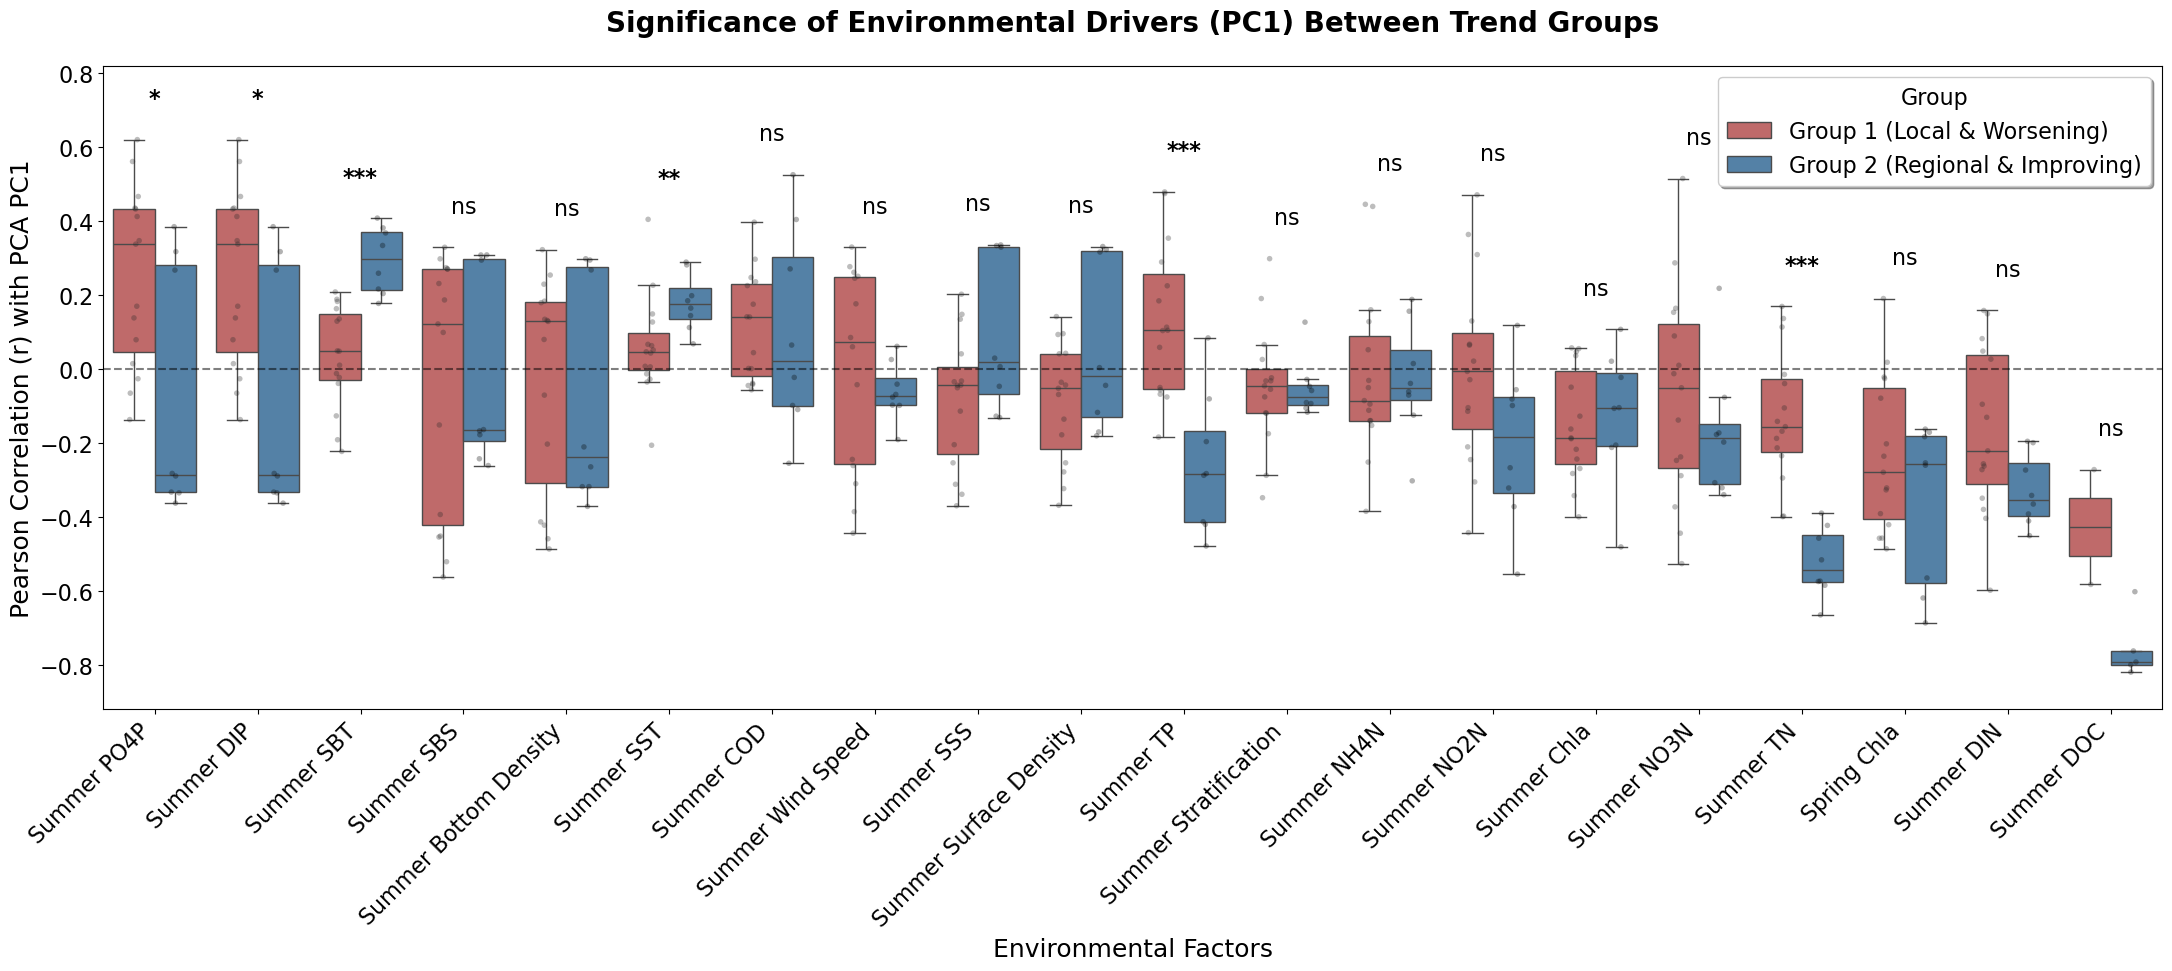

In [10]:
# 4b. Summary Driver Comparison (Grouped Plot with Significance)
import seaborn as sns
from scipy import stats

# 1. Prepare data for grouped plotting (Melt)
params_to_plot = [p for p in params_to_test if p in analysis_df.columns]
melted_df = analysis_df.melt(id_vars=['Station_ID', 'Group'], value_vars=params_to_plot, 
                             var_name='Parameter', value_name='Correlation')

# Clean up parameter names
melted_df['Parameter'] = melted_df['Parameter'].str.replace('_Corr_PC1', '').str.replace('_', ' ')

# 2. Calculate P-values for each parameter between groups
p_values = {}
for raw_param in params_to_plot:
    display_name = raw_param.replace('_Corr_PC1', '').replace('_', ' ')
    g1 = analysis_df[analysis_df['Group'] == 'Group 1 (Local & Worsening)'][raw_param].dropna()
    g2 = analysis_df[analysis_df['Group'] == 'Group 2 (Regional & Improving)'][raw_param].dropna()
    
    if len(g1) > 0 and len(g2) > 0:
        _, p = stats.mannwhitneyu(g1, g2, alternative='two-sided')
        p_values[display_name] = p
    else:
        p_values[display_name] = 1.0

# Sort parameters by median correlation (Group 1) for readability
param_order = melted_df.groupby('Parameter')['Correlation'].median().sort_values(ascending=False).index

plt.figure(figsize=(22, 10))

# 3. Create the Grouped Plot
ax = sns.boxplot(data=melted_df, x='Parameter', y='Correlation', hue='Group', 
                order=param_order, palette=['indianred', 'steelblue'], showfliers=False)

sns.stripplot(data=melted_df, x='Parameter', y='Correlation', hue='Group', 
              order=param_order, dodge=True, color='black', alpha=0.3, size=4, jitter=True)

# 4. Add Significance Annotations (Asterisks)
for i, param in enumerate(param_order):
    p = p_values.get(param, 1.0)
    
    # Determine annotation string
    if p < 0.001: sig_text = '***'
    elif p < 0.01: sig_text = '**'
    elif p < 0.05: sig_text = '*'
    else: sig_text = 'ns'
    
    # Position text slightly above the maximum value for this parameter
    y_max = melted_df[melted_df['Parameter'] == param]['Correlation'].max()
    ax.text(i, y_max + 0.08, sig_text, ha='center', va='bottom', color='black', 
            fontweight='bold' if sig_text != 'ns' else 'normal')

plt.axhline(0, color='black', linestyle='--', alpha=0.5)
plt.title("Significance of Environmental Drivers (PC1) Between Trend Groups", pad=25)
plt.ylabel("Pearson Correlation (r) with PCA PC1")
plt.xlabel("Environmental Factors")
plt.xticks(rotation=45, ha='right')

# 5. Move Legend Inside Top Right
handles, labels = ax.get_legend_handles_labels()
# Only take first two handles to exclude stripplot duplicates
plt.legend(handles[0:2], labels[0:2], title="Group", loc='upper right', frameon=True, shadow=True)

# Set Y-axis limit a bit higher to accommodate annotations
plt.ylim(melted_df['Correlation'].min() - 0.1, melted_df['Correlation'].max() + 0.2)

plt.tight_layout()
plt.show()

### PC2

Calculating Summer Chl-a correlations for PC2...


/tmp/ipykernel_916/2666776277.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=analysis_df_pc2, x='Group', y=param, ax=ax, palette=['indianred', 'steelblue'], showfliers=False)
/tmp/ipykernel_916/2666776277.py:77: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Group 1', 'Group 2'])
/tmp/ipykernel_916/2666776277.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=analysis_df_pc2, x='Group', y=param, ax=ax, palette=['indianred', 'steelblue'], showfliers=False)
/tmp/ipykernel_916/2666776277.py:77: UserWarning: set_ticklabels() should only be used with a fixed number of ticks,

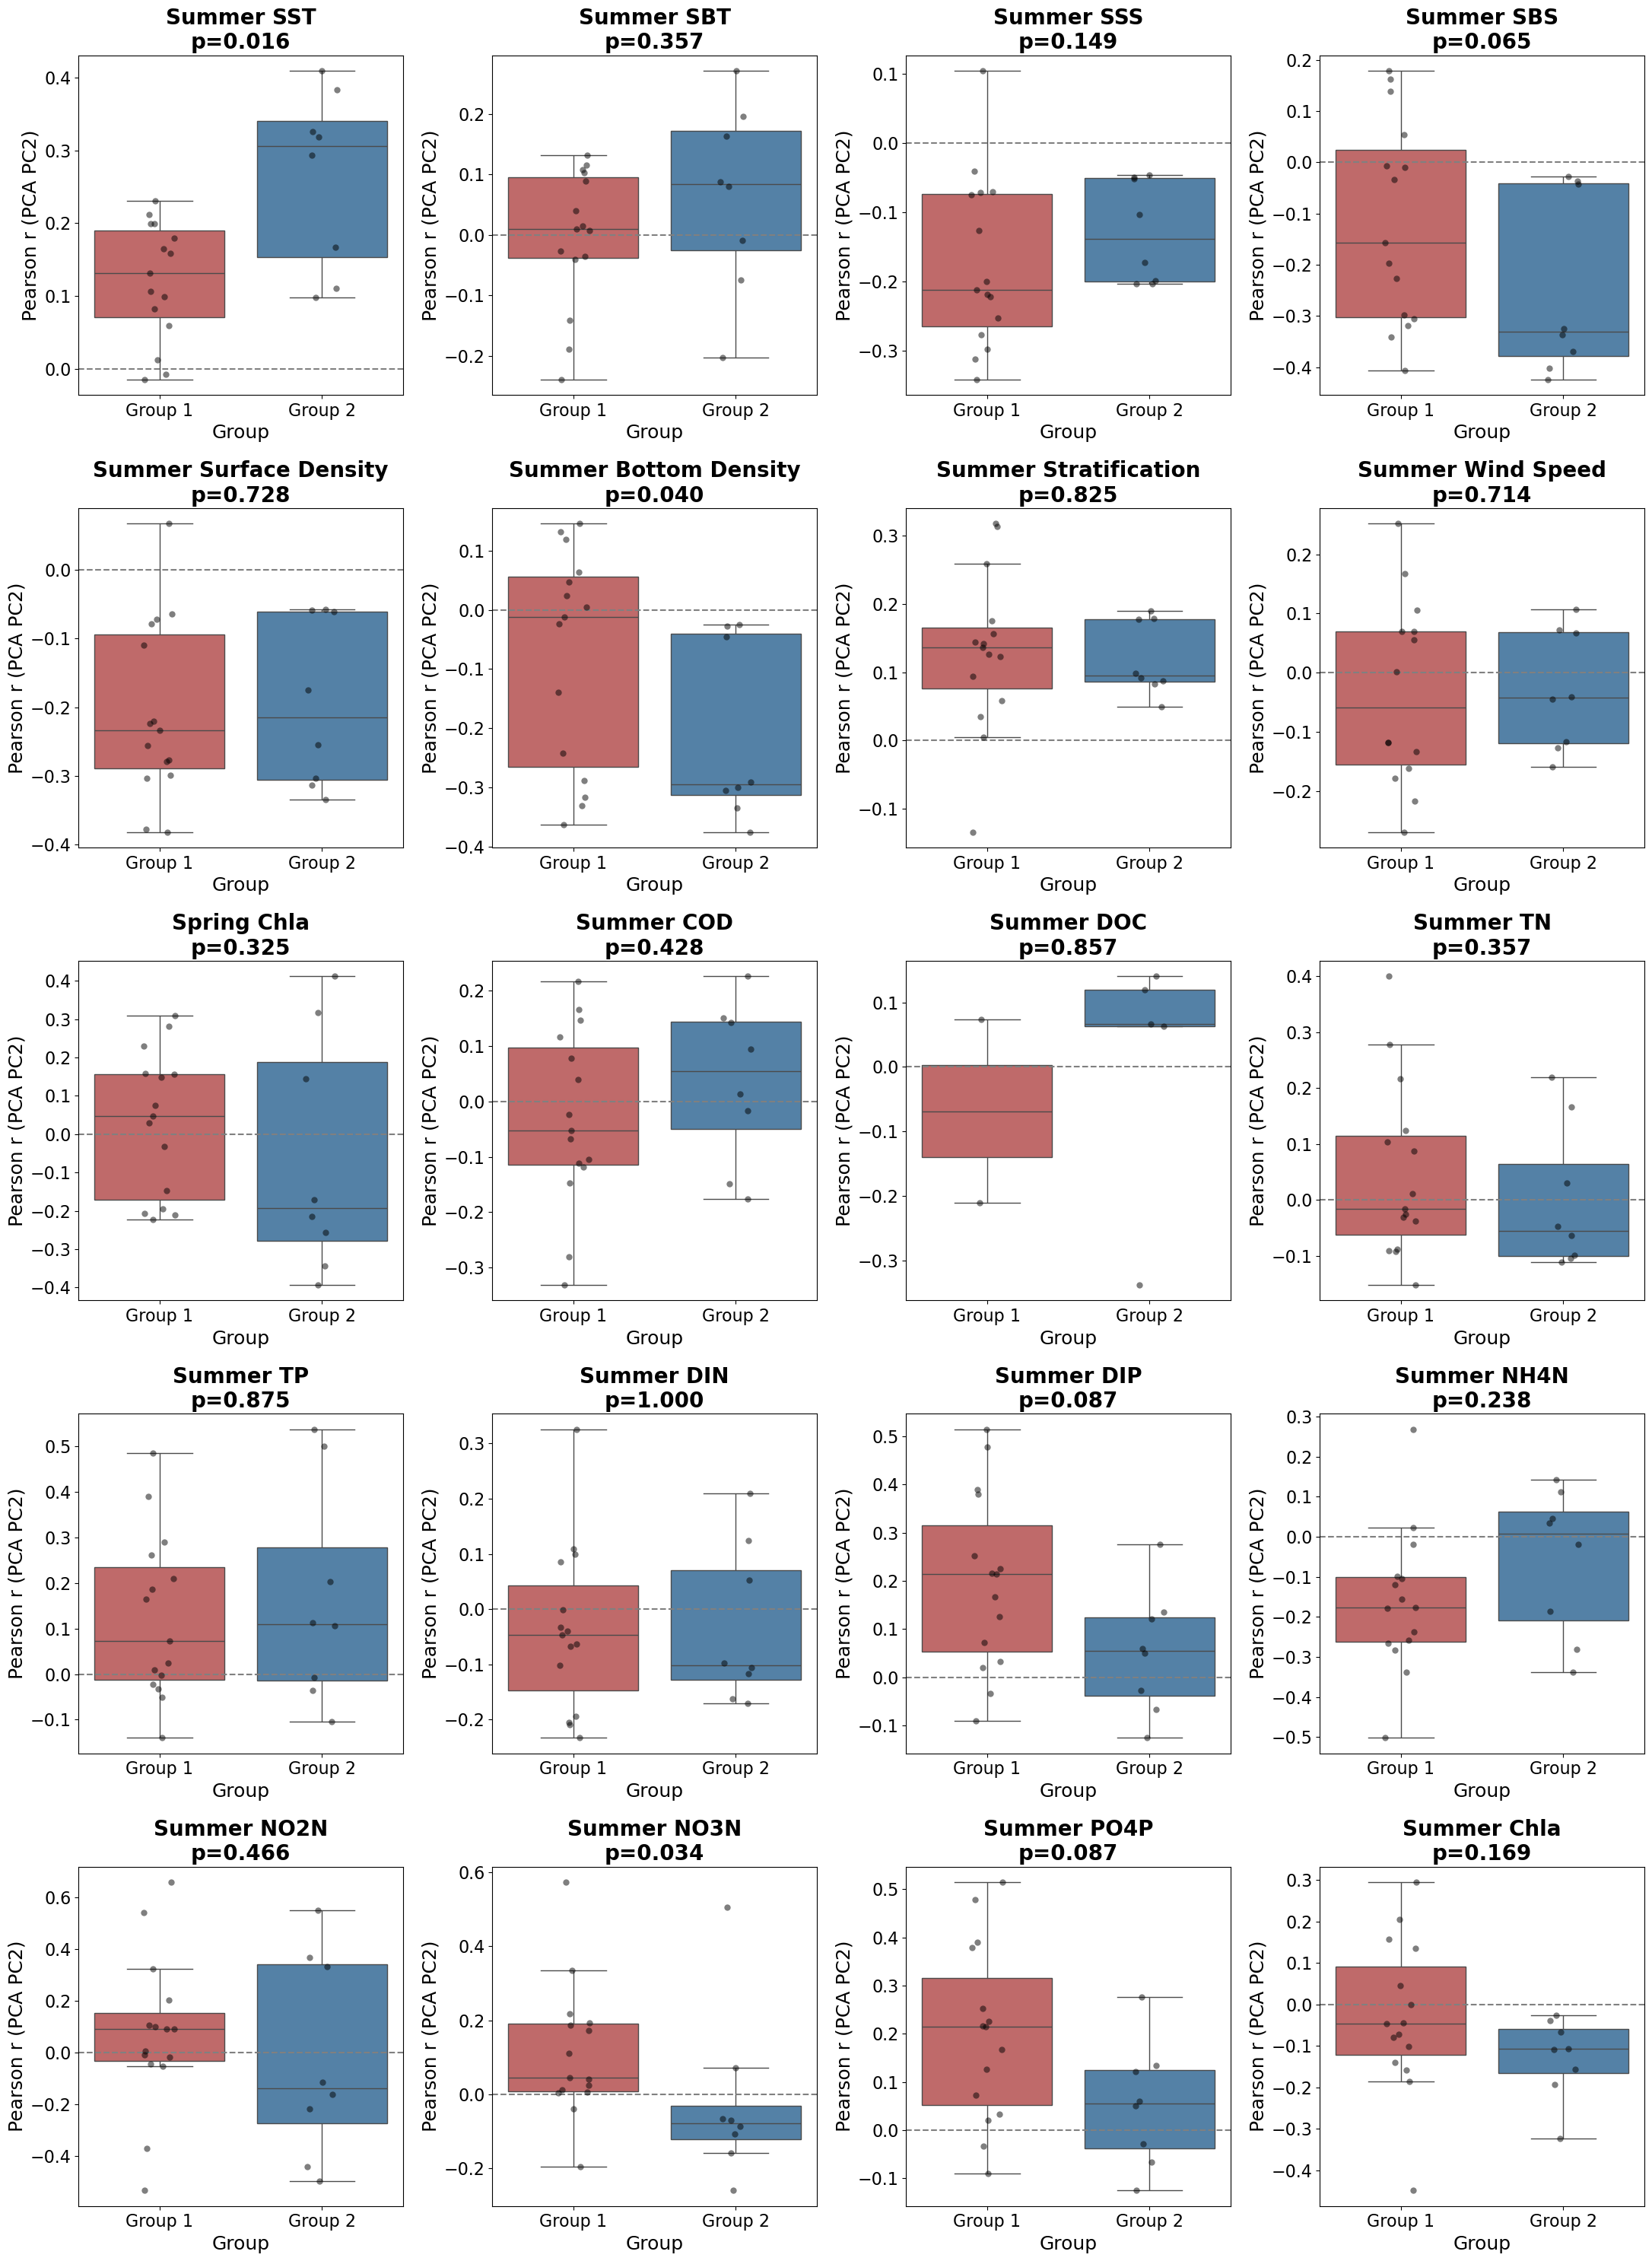

In [7]:
# 5. Driver Analysis (PCA Correlation Scores - PC2)
import math
from scipy.stats import pearsonr

# Load correlation data for PC2
corr_pc2_env = pd.read_csv(subset_dir / 'pca_env_corr_pc2.csv', dtype={'zettaicode': str})
corr_pc2_nutr = pd.read_csv(subset_dir / 'pca_nutr_corr_pc2.csv', dtype={'zettaicode': str})

# Filter parameters (same as PC1 logic)
params_env_pc2 = [c for c in corr_pc2_env.columns if c != 'zettaicode' and not c.endswith('_pval') and not c.endswith('_n') and c != 'Winter_Air_Temp']
params_nutr_pc2 = [c for c in corr_pc2_nutr.columns if c != 'zettaicode' and not c.endswith('_pval') and not c.endswith('_n')]

# Prepare PC2 Correlation DataFrame
pca_corr_pc2 = corr_pc2_env[['zettaicode'] + params_env_pc2].rename(columns={c: f"{c}_Corr_PC2" for c in params_env_pc2})
pca_corr_pc2 = pca_corr_pc2.merge(corr_pc2_nutr[['zettaicode'] + params_nutr_pc2].rename(columns={c: f"{c}_Corr_PC2" for c in params_nutr_pc2}), on='zettaicode', how='outer')

# Join with existing selected_stations (which contains Group assignments)
analysis_df_pc2 = selected_stations.merge(pca_corr_pc2, left_on='Station_ID', right_on='zettaicode', how='inner')

# --- Add Summer Chl-a Correlation for PC2 ---
if 'Summer_Chla_Corr_PC2' not in analysis_df_pc2.columns:
    print("Calculating Summer Chl-a correlations for PC2...")
    pca_scores = pd.read_csv(subset_dir / 'pca_scores.csv', index_col=0)
    pca_scores.index = pca_scores.index.astype(int)
    
    # Extract Summer Bottom Chl-a data
    mask = (merged_gdf['season'] == 'Summer') & (merged_gdf['saisuipoin'] == 2)
    chla_mat = merged_gdf[mask].groupby(['year', 'zettaicode'])['chlorophyl'].mean().unstack()
    
    chla_corrs_pc2 = {}
    for stn in analysis_df_pc2['Station_ID'].unique():
        if stn in chla_mat.columns:
            s_pc = pca_scores['PC2'] # Using PC2 scores here
            s_env = chla_mat[stn]
            common = s_pc.index.intersection(s_env.index)
            valid = s_pc.loc[common].notna() & s_env.loc[common].notna()
            if valid.sum() >= 5:
                r, _ = pearsonr(s_pc.loc[common][valid], s_env.loc[common][valid])
                chla_corrs_pc2[stn] = r
    
    analysis_df_pc2['Summer_Chla_Corr_PC2'] = analysis_df_pc2['Station_ID'].map(chla_corrs_pc2)

# Define list of PC2 parameters to visualize
params_to_test_pc2 = [f"{p}_Corr_PC2" for p in params_env_pc2 + params_nutr_pc2]
if 'Summer_Chla_Corr_PC2' not in params_to_test_pc2:
    params_to_test_pc2.append('Summer_Chla_Corr_PC2')

# Plotting Configuration
n_cols = 4
n_rows = math.ceil(len(params_to_test_pc2) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(22, 6 * n_rows))
axes = axes.flatten()

for i, param in enumerate(params_to_test_pc2):
    ax = axes[i]
    if param not in analysis_df_pc2.columns or analysis_df_pc2[param].dropna().empty:
        fig.delaxes(ax)
        continue
        
    g1_vals = analysis_df_pc2[analysis_df_pc2['Group'] == 'Group 1 (Local & Worsening)'][param].dropna()
    g2_vals = analysis_df_pc2[analysis_df_pc2['Group'] == 'Group 2 (Regional & Improving)'][param].dropna()
    
    # Statistical comparison
    if len(g1_vals) > 0 and len(g2_vals) > 0:
        stat, p = stats.mannwhitneyu(g1_vals, g2_vals, alternative='two-sided')
        p_str = f"p={p:.3f}"
    else:
        p_str = "N/A"
        
    sns.boxplot(data=analysis_df_pc2, x='Group', y=param, ax=ax, palette=['indianred', 'steelblue'], showfliers=False)
    sns.stripplot(data=analysis_df_pc2, x='Group', y=param, ax=ax, color='black', alpha=0.5, size=6, jitter=True)
    
    # Formatting
    title = param.replace('_Corr_PC2', '').replace('_', ' ')
    ax.set_title(f"{title}\n{p_str}")
    ax.set_ylabel('Pearson r (PCA PC2)')
    ax.set_xticklabels(['Group 1', 'Group 2'])
    ax.axhline(0, color='gray', linestyle='--')

# Cleanup extra subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

/tmp/ipykernel_916/3655496640.py:35: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=melted_df_pc2, x='Parameter', y='Correlation', hue='Group',


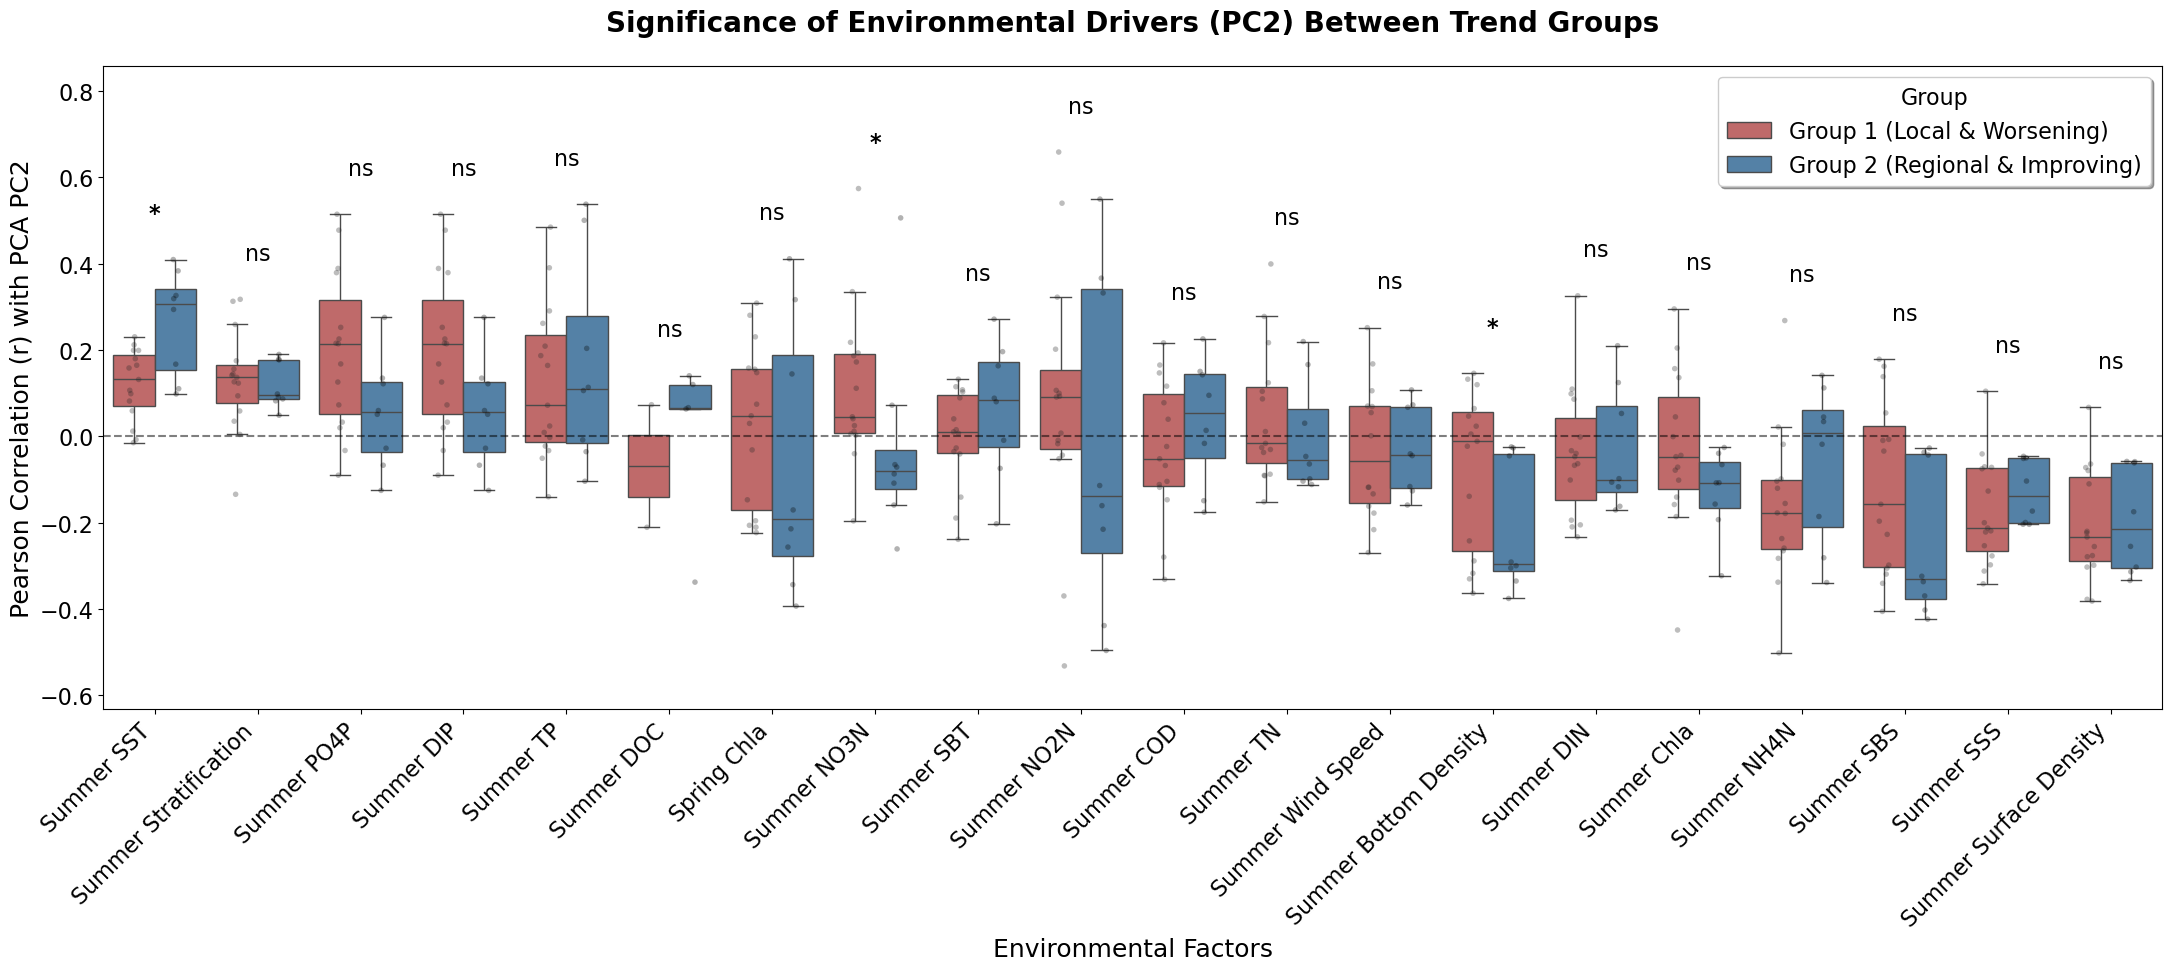

In [8]:
# 5b. Summary Driver Comparison (Grouped Plot with Significance - PC2)
import seaborn as sns
from scipy import stats

# 1. Prepare data for grouped plotting (Melt using PC2 dataframe)
params_to_plot_pc2 = [p for p in params_to_test_pc2 if p in analysis_df_pc2.columns]
melted_df_pc2 = analysis_df_pc2.melt(id_vars=['Station_ID', 'Group'], value_vars=params_to_plot_pc2, 
                                     var_name='Parameter', value_name='Correlation')

# Clean up parameter names for display (replace PC2 suffix)
melted_df_pc2['Parameter'] = melted_df_pc2['Parameter'].str.replace('_Corr_PC2', '').str.replace('_', ' ')

# 2. Calculate P-values for each parameter between groups for PC2
p_values_pc2 = {}
for raw_param in params_to_plot_pc2:
    display_name = raw_param.replace('_Corr_PC2', '').replace('_', ' ')
    g1 = analysis_df_pc2[analysis_df_pc2['Group'] == 'Group 1 (Local & Worsening)'][raw_param].dropna()
    g2 = analysis_df_pc2[analysis_df_pc2['Group'] == 'Group 2 (Regional & Improving)'][raw_param].dropna()
    
    if len(g1) > 0 and len(g2) > 0:
        _, p = stats.mannwhitneyu(g1, g2, alternative='two-sided')
        p_values_pc2[display_name] = p
    else:
        p_values_pc2[display_name] = 1.0

# Sort parameters by median correlation (Group 1) for readability
param_order_pc2 = melted_df_pc2.groupby('Parameter')['Correlation'].median().sort_values(ascending=False).index

plt.figure(figsize=(22, 10))

# 3. Create the Grouped Plot
ax = sns.boxplot(data=melted_df_pc2, x='Parameter', y='Correlation', hue='Group', 
                order=param_order_pc2, palette=['indianred', 'steelblue'], showfliers=False)

sns.stripplot(data=melted_df_pc2, x='Parameter', y='Correlation', hue='Group', 
              order=param_order_pc2, dodge=True, color='black', alpha=0.3, size=4, jitter=True)

# 4. Add Significance Annotations (Asterisks)
for i, param in enumerate(param_order_pc2):
    p = p_values_pc2.get(param, 1.0)
    
    # Determine annotation string
    if p < 0.001: sig_text = '***'
    elif p < 0.01: sig_text = '**'
    elif p < 0.05: sig_text = '*'
    else: sig_text = 'ns'
    
    # Position text slightly above the maximum value for this parameter
    y_max = melted_df_pc2[melted_df_pc2['Parameter'] == param]['Correlation'].max()
    ax.text(i, y_max + 0.08, sig_text, ha='center', va='bottom', color='black', 
            fontweight='bold' if sig_text != 'ns' else 'normal')

plt.axhline(0, color='black', linestyle='--', alpha=0.5)
plt.title("Significance of Environmental Drivers (PC2) Between Trend Groups", pad=25)
plt.ylabel("Pearson Correlation (r) with PCA PC2")
plt.xlabel("Environmental Factors")
plt.xticks(rotation=45, ha='right')

# 5. Legend management
handles, labels = ax.get_legend_handles_labels()
plt.legend(handles[0:2], labels[0:2], title="Group", loc='upper right', frameon=True, shadow=True)

# Set Y-axis limit
plt.ylim(melted_df_pc2['Correlation'].min() - 0.1, melted_df_pc2['Correlation'].max() + 0.2)

plt.tight_layout()
plt.show()

# Raw DO time series

Calculating raw correlations for selected stations...


/tmp/ipykernel_6289/2474072960.py:34: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, p = stats.pearsonr(do_vals[valid], param_vals[valid])
/tmp/ipykernel_6289/2474072960.py:34: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, p = stats.pearsonr(do_vals[valid], param_vals[valid])
/tmp/ipykernel_6289/2474072960.py:34: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, p = stats.pearsonr(do_vals[valid], param_vals[valid])
/tmp/ipykernel_6289/2474072960.py:34: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, p = stats.pearsonr(do_vals[valid], param_vals[valid])
/tmp/ipykernel_6289/2474072960.py:34: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, p = stats.pearsonr(do_vals[valid], param_vals[valid])
/tmp/ipykernel_6289/2474072960.py:34: Constan

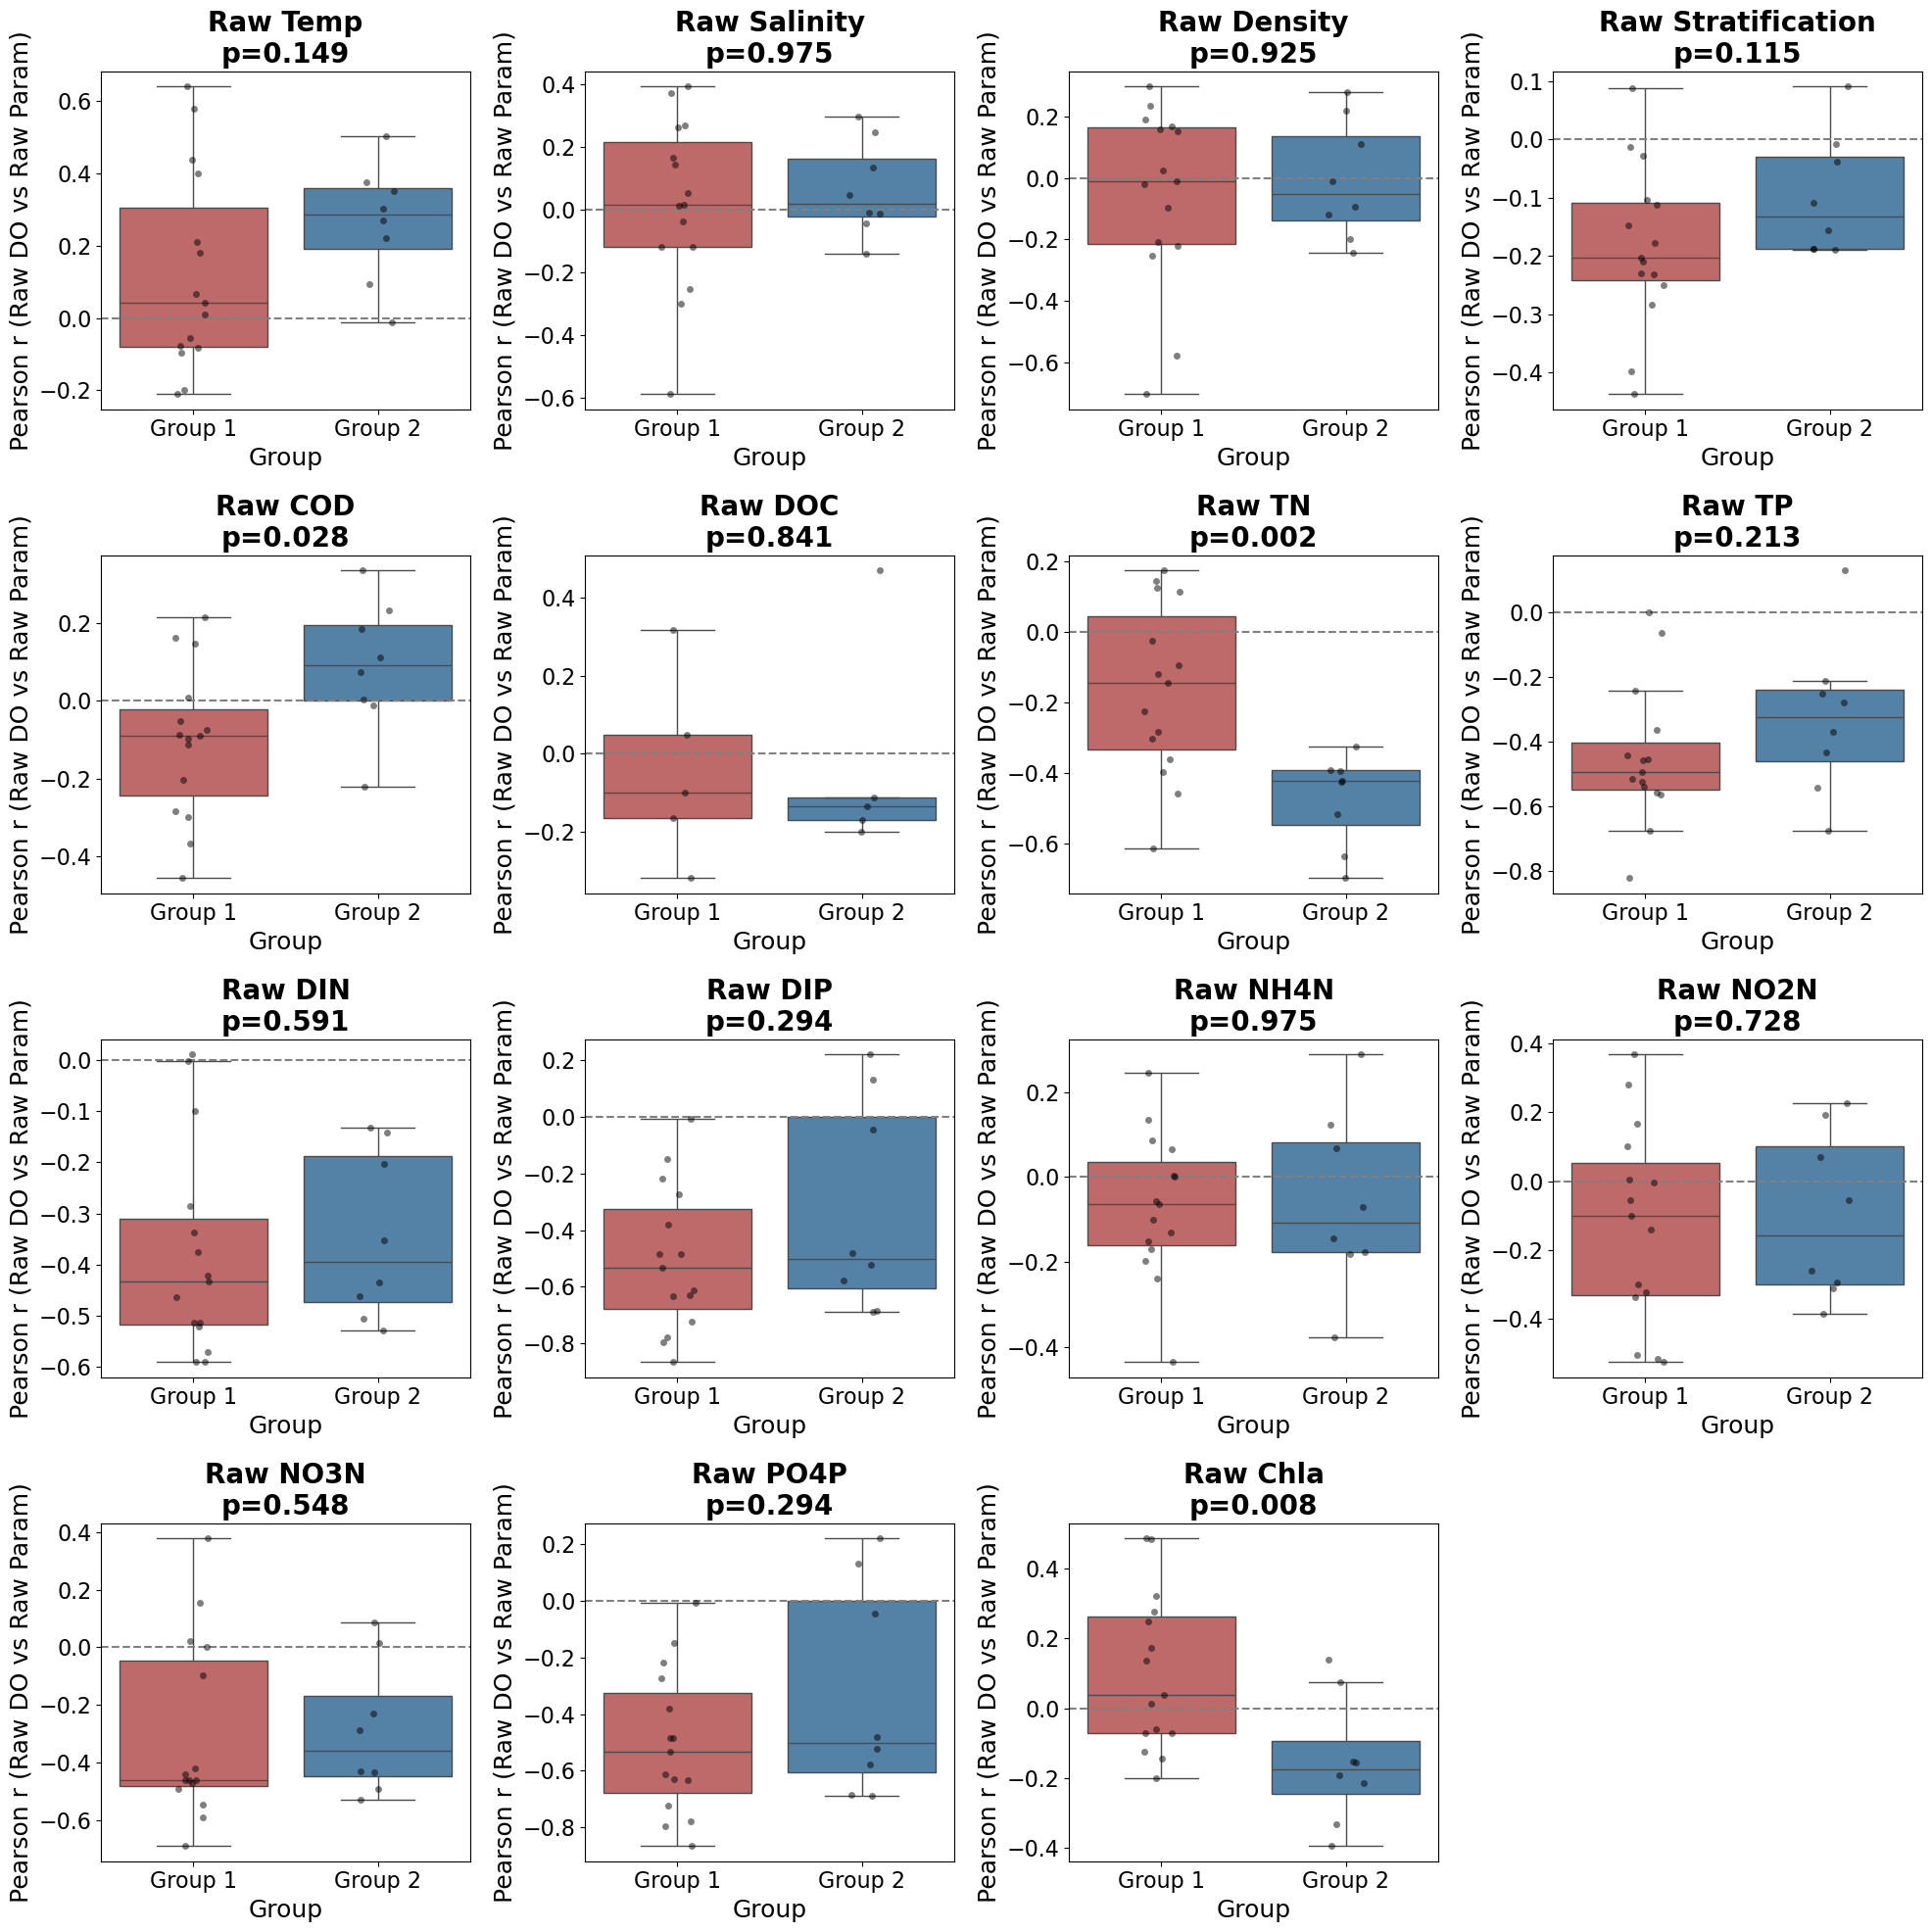

In [9]:
# 5. Driver Analysis (Raw DO Time Series)
import math
print("Calculating raw correlations for selected stations...")

def calc_raw_corr(station_id, param_col, merged_data):
    st_data = merged_data[(merged_data['zettaicode'] == station_id) & (merged_data['surveymont'] == REP_MONTH_SUMMER)]
    st_data_bottom = st_data[st_data['saisuipoin'] == 2].sort_values('year')
    
    do_vals = pd.to_numeric(st_data_bottom['do_'], errors='coerce')
    
    # Calculate DIN/DIP if requested, or pull from column
    if param_col == 'din':
        # DIN = NH4-N + NO2-N + NO3-N
        cols = ['nh4n', 'no2n', 'no3n']
        available_cols = [c for c in cols if c in st_data_bottom.columns]
        if available_cols:
            param_vals = st_data_bottom[available_cols].apply(pd.to_numeric, errors='coerce').sum(axis=1, min_count=1)
        else:
            param_vals = pd.Series(np.nan, index=st_data_bottom.index)
    elif param_col == 'dip':
        # DIP = PO4-P
        col = 'po4p'
        if col in st_data_bottom.columns:
            param_vals = pd.to_numeric(st_data_bottom[col], errors='coerce')
        else:
            param_vals = pd.Series(np.nan, index=st_data_bottom.index)
    elif param_col in st_data_bottom.columns:
        param_vals = pd.to_numeric(st_data_bottom[param_col], errors='coerce')
    else:
        param_vals = pd.Series(np.nan, index=st_data_bottom.index)
    
    valid = ~(do_vals.isna() | param_vals.isna())
    if valid.sum() > 5:
        r, p = stats.pearsonr(do_vals[valid], param_vals[valid])
        return r
    return np.nan

# Define all raw parameters to test against raw DO
raw_params = {
    'Temp': 'wtemp', 'Salinity': 'salt', 'Density': 'density', 
    'Stratification': 'stratification', 'COD': 'cod', 'DOC': 'doc', 
    'TN': 'tn', 'TP': 'tp', 'DIN': 'din', 'DIP': 'dip', 
    'NH4N': 'nh4n', 'NO2N': 'no2n', 'NO3N': 'no3n', 
    'PO4P': 'po4p', 'Chla': 'chlorophyl'
}

raw_results = []
for idx, row in analysis_df.iterrows():
    sid = row['Station_ID']
    res = {'Station_ID': sid, 'Group': row['Group']}
    for name, col in raw_params.items():
        res[name] = calc_raw_corr(sid, col, merged_gdf)
    raw_results.append(res)

raw_df = pd.DataFrame(raw_results)

# Statistical Testing and Plotting
params_to_test_raw = list(raw_params.keys())
n_cols = 4
n_rows = math.ceil(len(params_to_test_raw) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5 * n_rows))
axes = axes.flatten()

for i, param in enumerate(params_to_test_raw):
    ax = axes[i]
    if param not in raw_df.columns or raw_df[param].dropna().empty:
        fig.delaxes(ax)
        continue
        
    g1_vals = raw_df[raw_df['Group'] == 'Group 1 (Local & Worsening)'][param].dropna()
    g2_vals = raw_df[raw_df['Group'] == 'Group 2 (Regional & Improving)'][param].dropna()
    
    if len(g1_vals) > 0 and len(g2_vals) > 0:
        stat, p = stats.mannwhitneyu(g1_vals, g2_vals, alternative='two-sided')
        p_str = f"p={p:.3f}"
    else:
        p_str = "N/A"
        
    sns.boxplot(data=raw_df, x='Group', y=param, ax=ax, palette=['indianred', 'steelblue'], showfliers=False)
    # Add points on top of boxplot
    sns.stripplot(data=raw_df, x='Group', y=param, ax=ax, color='black', alpha=0.5, size=5, jitter=True)
    
    ax.set_title(f"Raw {param}\n{p_str}")
    ax.set_ylabel('Pearson r (Raw DO vs Raw Param)')
    ax.set_xticklabels(['Group 1', 'Group 2'])
    ax.axhline(0, color='gray', linestyle='--')

# Hide unused axes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

/tmp/ipykernel_6289/3497486432.py:32: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=melted_raw_df, x='Parameter', y='Correlation', hue='Group',


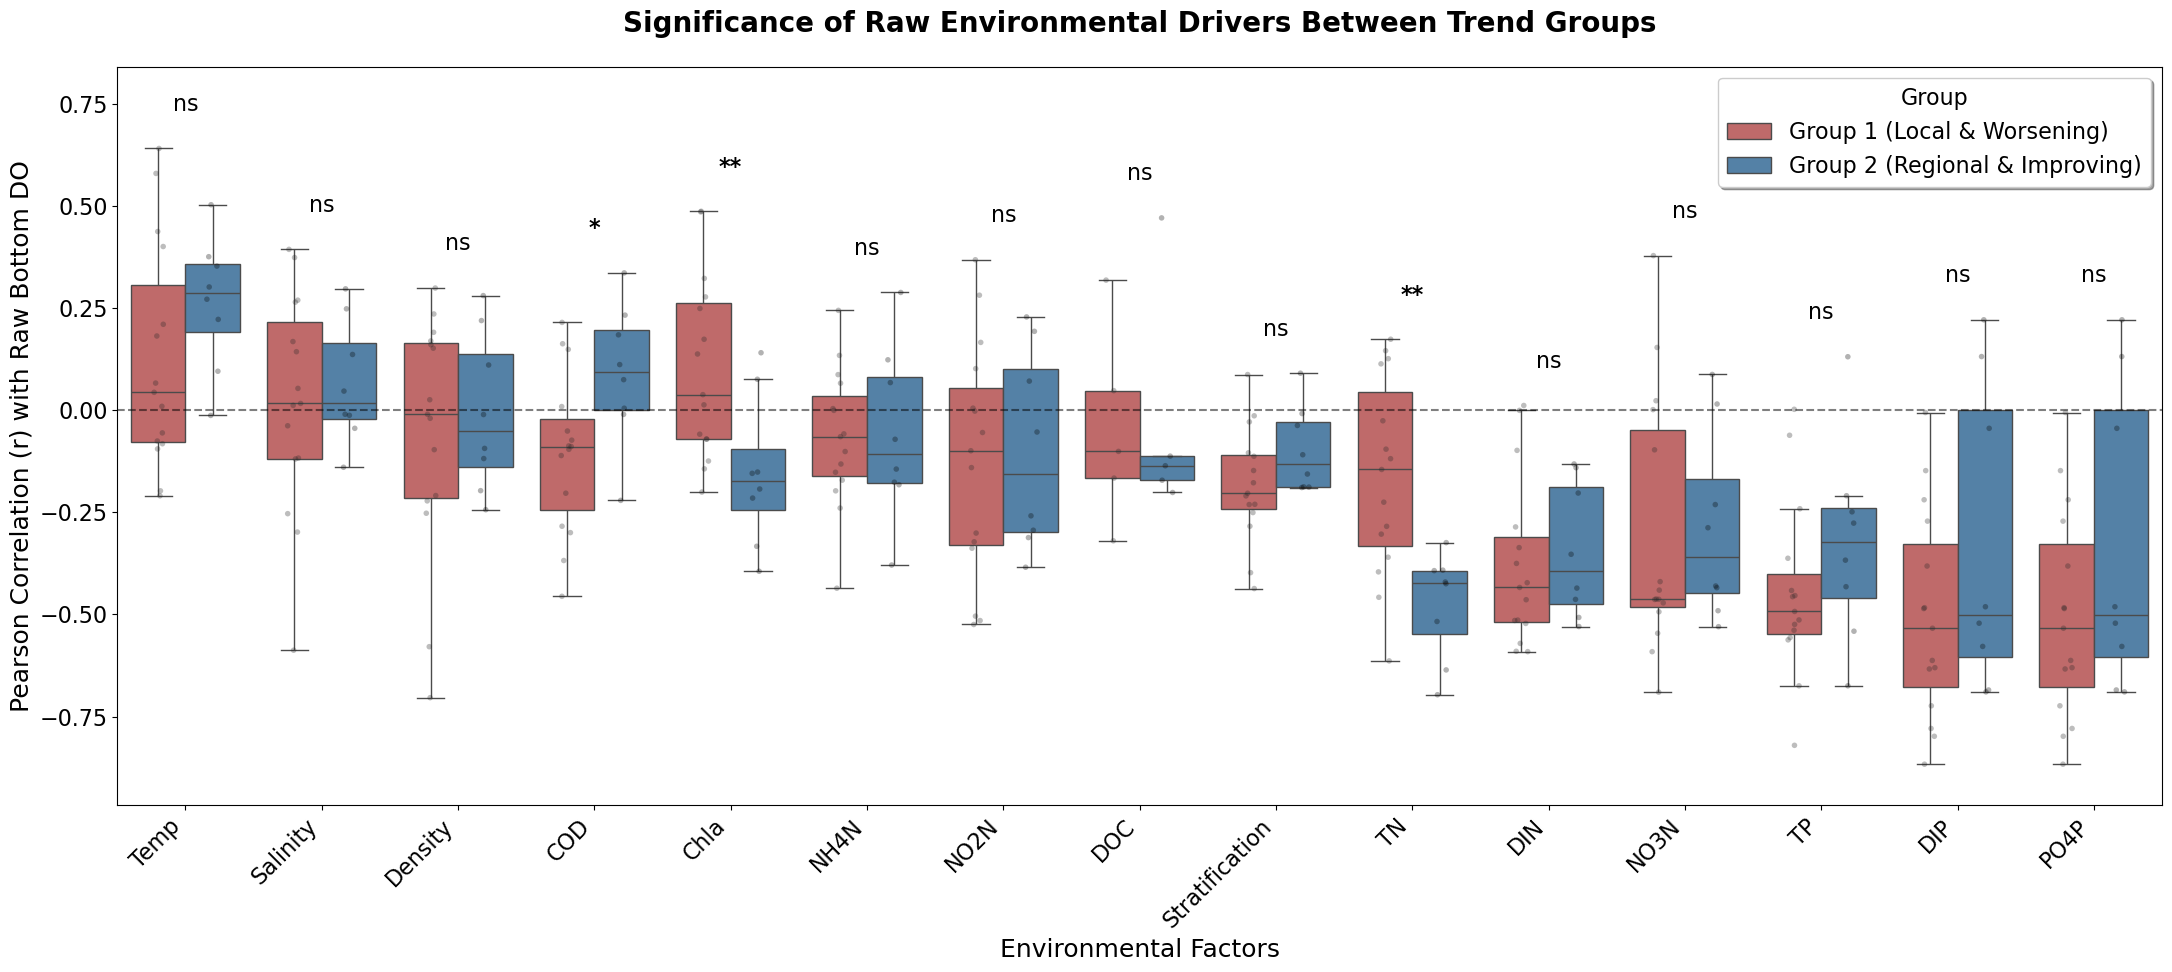

In [10]:
# 5b. Summary Raw Driver Comparison (Grouped Plot with Significance)
import seaborn as sns
from scipy import stats

# 1. Prepare data for grouped plotting (Melt)
# Exclude non-parameter columns
params_to_plot_raw = list(raw_params.keys())
melted_raw_df = raw_df.melt(id_vars=['Station_ID', 'Group'], value_vars=params_to_plot_raw, 
                             var_name='Parameter', value_name='Correlation')

# 2. Calculate P-values for each raw parameter between groups
p_values_raw = {}
for param in params_to_plot_raw:
    g1 = raw_df[raw_df['Group'] == 'Group 1 (Local & Worsening)'][param].dropna()
    g2 = raw_df[raw_df['Group'] == 'Group 2 (Regional & Improving)'][param].dropna()
    
    if len(g1) > 0 and len(g2) > 0:
        _, p = stats.mannwhitneyu(g1, g2, alternative='two-sided')
        p_values_raw[param] = p
    else:
        p_values_raw[param] = 1.0

# Sort parameters by median correlation for readability
param_order_raw = melted_raw_df.groupby('Parameter')['Correlation'].median().sort_values(ascending=False).index

plt.figure(figsize=(22, 10))

# 3. Create the Grouped Plot
ax = sns.boxplot(data=melted_raw_df, x='Parameter', y='Correlation', hue='Group', 
                order=param_order_raw, palette=['indianred', 'steelblue'], showfliers=False)

sns.stripplot(data=melted_raw_df, x='Parameter', y='Correlation', hue='Group', 
              order=param_order_raw, dodge=True, color='black', alpha=0.3, size=4, jitter=True)

# 4. Add Significance Annotations (Asterisks)
for i, param in enumerate(param_order_raw):
    p = p_values_raw.get(param, 1.0)
    
    if p < 0.001: sig_text = '***'
    elif p < 0.01: sig_text = '**'
    elif p < 0.05: sig_text = '*'
    else: sig_text = 'ns'
    
    y_max = melted_raw_df[melted_raw_df['Parameter'] == param]['Correlation'].max()
    # Add annotation slightly above the max point
    ax.text(i, y_max + 0.08, sig_text, ha='center', va='bottom', color='black', 
            fontweight='bold' if sig_text != 'ns' else 'normal')

plt.axhline(0, color='black', linestyle='--', alpha=0.5)
plt.title("Significance of Raw Environmental Drivers Between Trend Groups", pad=25)
plt.ylabel("Pearson Correlation (r) with Raw Bottom DO")
plt.xlabel("Environmental Factors")
plt.xticks(rotation=45, ha='right')

# 5. Legend inside top right
handles, labels = ax.get_legend_handles_labels()
plt.legend(handles[0:2], labels[0:2], title="Group", loc='upper right', frameon=True, shadow=True)

# Set Y-axis limit to accommodate annotations
plt.ylim(melted_raw_df['Correlation'].min() - 0.1, melted_raw_df['Correlation'].max() + 0.2)

plt.tight_layout()
plt.show()

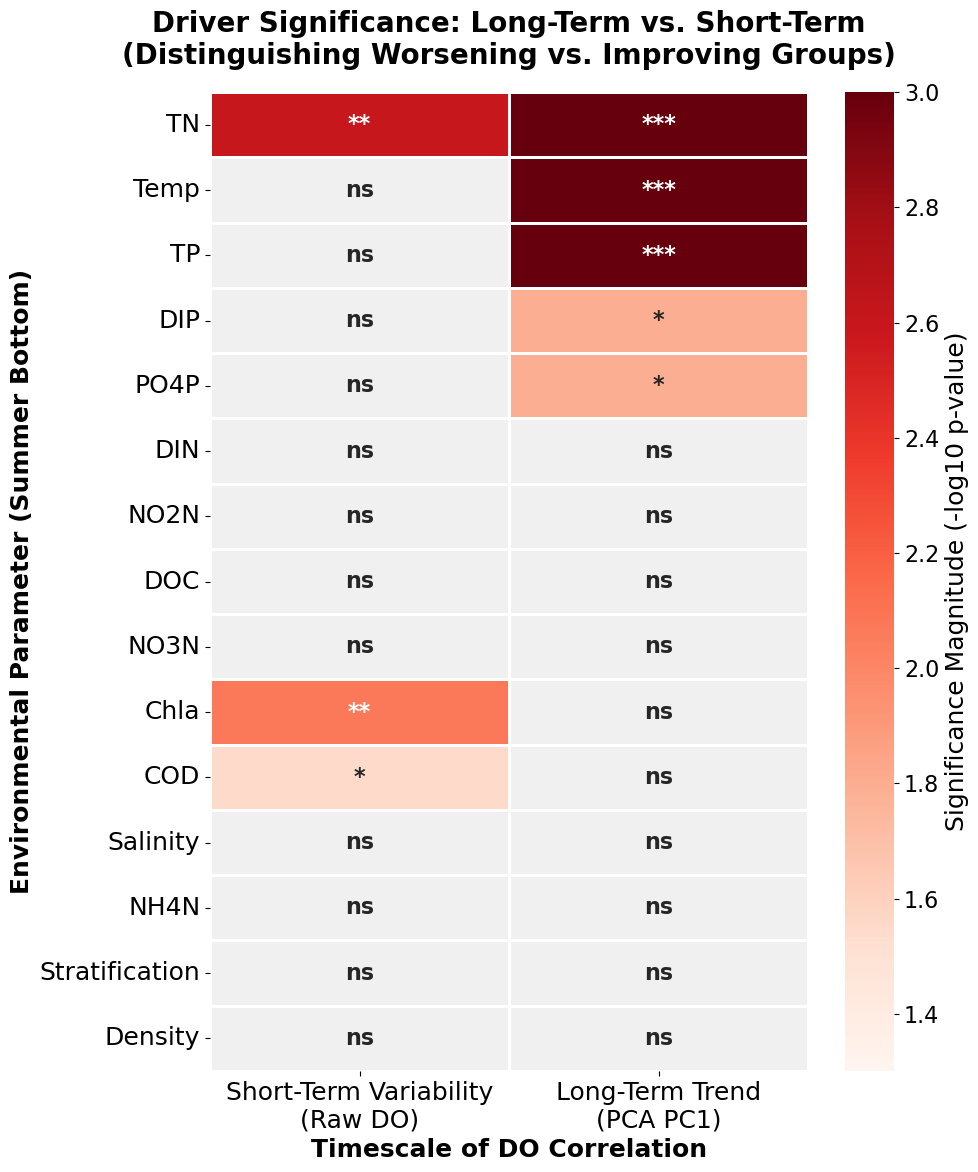

In [12]:
# 6. Significance Comparison: Long-term vs Short-term Heatmap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define mapping between Raw parameters and PCA parameters
# Note: Raw parameters represent summer bottom measurements
param_mapping = {
    'Temp': 'Summer SBT',
    'Salinity': 'Summer SBS',
    'Density': 'Summer Bottom Density',
    'Stratification': 'Summer Stratification',
    'Chla': 'Summer Chla',
    'COD': 'Summer COD',
    'DOC': 'Summer DOC',
    'TN': 'Summer TN',
    'TP': 'Summer TP',
    'DIN': 'Summer DIN',
    'DIP': 'Summer DIP',
    'PO4P': 'Summer PO4P',
    'NH4N': 'Summer NH4N',
    'NO2N': 'Summer NO2N',
    'NO3N': 'Summer NO3N'
}

# 2. Build combined dataframe for comparison
comp_data = []
for raw_name, pca_name in param_mapping.items():
    # Fetch p-values from previously calculated dictionaries (default to 1.0 if missing)
    p_raw = p_values_raw.get(raw_name, 1.0)
    p_pca = p_values.get(pca_name, 1.0)
    
    comp_data.append({
        'Parameter': raw_name,
        'Short-Term Variability\n(Raw DO)': p_raw,
        'Long-Term Trend\n(PCA PC1)': p_pca
    })

comp_df = pd.DataFrame(comp_data).set_index('Parameter')

# 3. Convert p-values to -log10 for heatmap intensity (higher = more significant)
log_df = -np.log10(comp_df + 1e-10)

# 4. Create text annotations (*, **, ***, ns)
annot_df = comp_df.copy()
for col in annot_df.columns:
    annot_df[col] = annot_df[col].apply(
        lambda p: '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'ns'))
    )

# Sort the heatmap so the most significant Long-Term drivers are at the top
log_df = log_df.sort_values(by=['Long-Term Trend\n(PCA PC1)', 'Short-Term Variability\n(Raw DO)'], ascending=[False, False])
annot_df = annot_df.reindex(log_df.index)

# 5. Plot the Heatmap
plt.figure(figsize=(10, 12))

# Create a colormap that is Grey for non-significant, and Red gradient for significant
cmap = sns.color_palette("Reds", as_cmap=True)
cmap.set_under("#f0f0f0") # Light grey for p >= 0.05

# vmin is set to -log10(0.05) ~ 1.301. Anything below this threshold gets the 'under' color (grey)
ax = sns.heatmap(log_df, annot=annot_df, fmt="", cmap=cmap, 
                 vmin=-np.log10(0.05), vmax=-np.log10(0.001), 
                 linewidths=2, linecolor='white', square=False,
                 cbar_kws={'label': 'Significance Magnitude (-log10 p-value)'},
                 annot_kws={'size': 16, 'weight': 'bold'})

# Styling
plt.title("Driver Significance: Long-Term vs. Short-Term\n(Distinguishing Worsening vs. Improving Groups)", pad=20, weight='bold')
plt.ylabel("Environmental Parameter (Summer Bottom)", weight='bold')
plt.xlabel("Timescale of DO Correlation", weight='bold')

# Adjust tick labels
plt.xticks(fontsize=18)
plt.yticks(fontsize=18, rotation=0)

plt.tight_layout()
plt.show()

## 5. Local Mechanism Analysis (Raw Time-Series)

To verify the regional findings, we perform a station-by-station correlation analysis using **raw time-series data**. 
*   **Method:** Direct Pearson correlation between raw DO measurements and raw environmental/nutrient concentrations at each specific station.
*   **Goal:** Confirm if the localized mechanisms (e.g., local nutrient spikes) match the regional sensitivity patterns.

Edit: Moved the code to script to make this notebook lighter.